In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon-STACK.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/farahjstack/eds220-hwk2.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   object
dtypes: int64(1), object(4)
memory usage: 333.7+ KB
[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated 

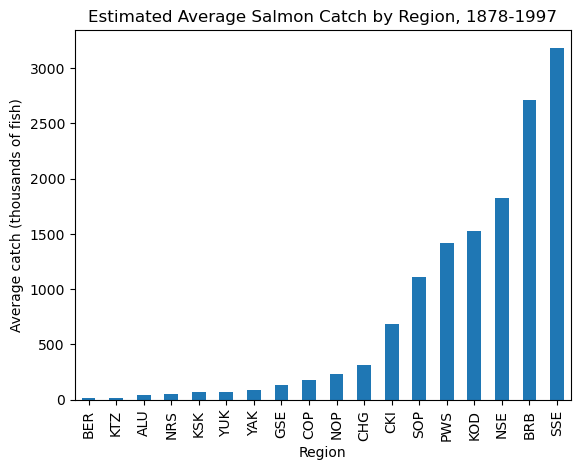

In [37]:
# FINAL CODE

# Import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import dataset
catch_data = pd.read_csv("data/salmon_data.csv")

# Explore the data
# first few rows
catch_data.head()

# Rows and columns
catch_data.shape

# Column types, rows, and non-null counts
catch_data.info()

# Check data types of each column
catch_data.dtypes

# Unique values in the Region column
catch_data["Region"].unique()

notes_unique = catch_data["notesRegCode"].unique()
print(notes_unique)

# Clean the data
catch_data = catch_data.drop(columns=['notesRegCode'])

catch_I = catch_data[catch_data['Catch'] == 'I']
catch_I 

# Update the value I to 1, using the index from catch_1
catch_data.loc[catch_I.index, 'Catch'] = 1

# Access the updated row to verify the change
catch_1 = catch_data.loc[catch_I.index]
catch_1

# Make Catch to int64 and assign it back
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# 2. Store and show the column's data type
catch_column_type = catch_data['Catch'].dtype

catch_column_type

# Split rows by region, [['Catch]] selects the Catch column and .mean() averages it within each group.
# [[]] keeps a dataframe, rather than a [], which keeps a pandas.series

avg_region = catch_data.groupby('Region')[['Catch']].mean()
avg_region


ax = (avg_region
      .sort_values('Catch')   # order bars by magnitude (increasing)
      .plot(kind='bar', legend=False))

ax.set_title('Estimated Average Salmon Catch by Region, 1878-1997')
ax.set_xlabel('Region')
ax.set_ylabel('Average catch (thousands of fish)')

plt.show()



## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [2]:
# a. Import packages and read in data

import pandas as pd
import numpy as np


catch_data = pd.read_csv("data/salmon_data.csv")

catch_data.head()

,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [3]:
# b. Preliminary data exploration

# Rows and columns
catch_data.shape

(8540, 5)

In [4]:
# Column types, rows, and non-null counts
catch_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8540 entries, 0 to 8539
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Region        8540 non-null   object
 1   Year          8540 non-null   int64 
 2   notesRegCode  1415 non-null   object
 3   Species       8540 non-null   object
 4   Catch         8540 non-null   object
dtypes: int64(1), object(4)
memory usage: 333.7+ KB


In [5]:
# Check data types of each column
catch_data.dtypes

Region          object
Year             int64
notesRegCode    object
Species         object
Catch           object
dtype: object

In [6]:
# Unique values in the Region column
catch_data["Region"].unique()

array(['SSE', 'NSE', 'YAK', 'GSE', 'BER', 'COP', 'PWS', 'CKI', 'BRB',
       'KSK', 'YUK', 'NRS', 'KTZ', 'KOD', 'CHG', 'SOP', 'ALU', 'NOP'],
      dtype=object)

In [7]:
# Check unique values in Species column
catch_data["Species"].unique()

array(['Chinook', 'Sockeye', 'Coho', 'Pink', 'Chum'], dtype=object)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

Before doing any analysis, I wanted to understand the basic structure of the data and check whether it was ready to use. I used `shape` to see how many rows and columns there are. I used `info()` and `dtypes` to see the column names, the data type of each column, and how many non-null values each one has. This tells me whether the columns are stored the way I expect (for example, numbers as numbers) and whether any columns have missing data. I then looked at the unique values in `Region` and `Species` because these are the categorical variables that I would most likely use to group or compare the data later.

I learned:

- The data frame has 8,540 rows and 5 columns: `Region`, `Year`, `notesRegCode`, `Species`, and `Catch`.

- `Year` is stored as an integer, as expected. `Region`, `Species`, and `notesRegCode` are stored as text.

- `notesRegCode` is the only column with missing values. Only 1,415 of the 8,540 rows have a non-null value, while every other column is complete. This suggests the column only has entries when there is something special to note about a row.

- There are 18 unique regions, labeled with short codes (for example, `SSE`, `BRB`, `KOD`), and 5 salmon species: Chinook, Sockeye, Coho, Pink, and Chum. The region codes are abbreviations, so I would need the dataset documentation to know exactly what area each one refers to.

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [8]:
notes_unique = catch_data["notesRegCode"].unique()
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [9]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [10]:
# Remove notesRegCode column
catch_data = catch_data.drop(columns=['notesRegCode'])

# Verify the column is gone
catch_data.columns


Index(['Region', 'Year', 'Species', 'Catch'], dtype='object')

In [11]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


_Each column has the expected data type. However,`Catch` is stored as text, which I did not expect because it should be a number. This means something in the column is not a valid number, and I will need to find it and convert the column to numeric before I can sum, average, or plot catch._

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [13]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [14]:
catch_I = catch_data[catch_data['Catch'] == 'I']
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [15]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [24]:

# Update the value I to 1, using the index from catch_1
catch_data.loc[catch_I.index, 'Catch 1'] = 1

# Access the updated row to verify the change
catch_1 = catch_data.loc[catch_I.index]

# Print catch_1
catch_1

,Region,Year,Species,Catch,Catch 1
400,GSE,1955,Chinook,1,1.0


<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [27]:

# Make Catch to int64 and assign it back
catch_data['Catch'] = catch_data['Catch'].astype('int64')

# 2. Store and show the column's data type
catch_column_type = catch_data['Catch'].dtype

catch_column_type

dtype('int64')

In [28]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [31]:
# Split rows by region, [['Catch]] selects the Catch column and .mean() averages it within each group.
# [[]] keeps a dataframe, rather than a [], which keeps a pandas.series

avg_region = catch_data.groupby('Region')[['Catch']].mean()
avg_region

,Catch
Region,
ALU,40.383908
BER,16.372549
BRB,2709.796491
CHG,315.487273
CKI,683.571429
COP,179.223404
GSE,133.841463
KOD,1528.350000
KSK,67.642353


In [32]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

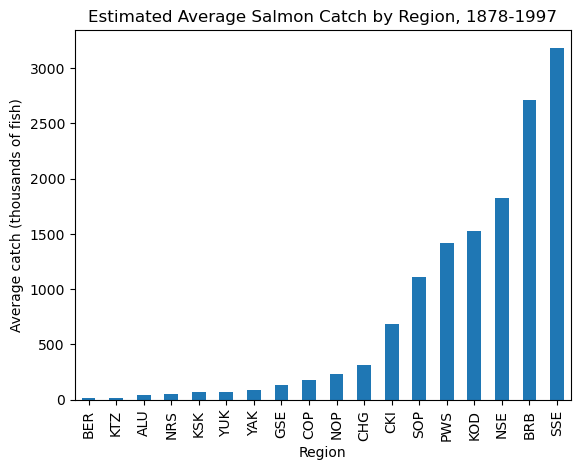

In [34]:
# Import package for making bar plots
import matplotlib.pyplot as plt

ax = (avg_region
      .sort_values('Catch')   # order bars by magnitude (increasing)
      .plot(kind='bar', legend=False))

ax.set_title('Estimated Average Salmon Catch by Region, 1878-1997')
ax.set_xlabel('Region')
ax.set_ylabel('Average catch (thousands of fish)')

plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

The plot shows the estimated avergae commerical salmon catch (in thousands of fish) for each Alaska management area from 1878 to 1997. Average catch varies enormously between areas. Southern Southeast Alaska (SSE) has the highest average, at about 
3,200  fish, followed by Bristol Bay (BRB) at about 2,700 fish and Northern Southeast Alaska (NSE) at about 1,800 fish. The lowest are the Bering River, Kotzebue, and Aleutian Islands areas, at only a few tens of thousands of fish or less. Overall, the Southeat nad Bristol Bay areas dominate the catch, and the northern and western areas such as Kotzebue, Norton Sound, the Yukon, and the Kuskokwim contribute very little.

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [35]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!